**DATA PREPROCESSING & FEATURE ENGINEERING**

In [118]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pandas.core.indexes.period import period_range
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
df_raw = pd.read_csv('/content/indonesia_ecommerce_sales_challenging.csv', sep=';')
df = df_raw.copy()
print('Ukuran awal:', df_raw.shape)
display(df_raw.head())

Ukuran awal: (18868, 19)


,order_id,total_qty,total_weight_gr,total_returned_qty,Total Diskon,product_categories,num_product_categories,Status Pesanan,Alasan Pembatalan,Opsi Pengiriman,Metode Pembayaran,Kota/Kabupaten,Provinsi,Ongkos Kirim Dibayar oleh Pembeli,Estimasi Potongan Biaya Pengiriman,Total Pembayaran,Perkiraan Ongkos Kirim,Waktu Pesanan Dibuat,order_date
0,ORD_0000001,2.0,2000,0,0,Celengan,1,Selesai,Tidak dibatalkan,Reguler (Cashless)-SPX Standard,Saldo ShopeePay,KOTA SERANG,BANTEN,0,10000,38300,10000,2024-04-01 00:15,2024-04-01
1,ORD_0000002,1.0,500,0,0,Celengan,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA SEMARANG,JAWA TENGAH,0,14500,18576,14500,2024-04-01 01:47,2024-04-01
2,ORD_0000003,1.0,500,0,0,Celengan,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,SeaBank Bayar Instan,KAB. BOGOR,JAWA BARAT,0,8000,7069,8000,2024-04-01 04:25,2024-04-01
3,ORD_0000004,2.0,400,0,0,Mangkok Sambal / Saus,1,Selesai,Tidak dibatalkan,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA JAMBI,JAMBI,0,20000,32200,20000,2024-04-01 04:41,2024-04-01
4,ORD_0000005,3.0,3600,0,0,"Keranjang, Other, Tempat Nasi",3,Batal,Dibatalkan oleh Pembeli. Alasan: Ubah Pesanan ...,Hemat Kargo-SPX Hemat,COD (Bayar di Tempat),KOTA TANGERANG,BANTEN,0,0,0,8000,2024-04-01 06:12,2024-04-01


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18868 entries, 0 to 18867
Data columns (total 19 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   order_id                            18868 non-null  object 
 1   total_qty                           18585 non-null  float64
 2   total_weight_gr                     18868 non-null  int64  
 3   total_returned_qty                  18868 non-null  int64  
 4   Total Diskon                        18868 non-null  int64  
 5   product_categories                  18868 non-null  object 
 6   num_product_categories              18868 non-null  int64  
 7   Status Pesanan                      18868 non-null  object 
 8   Alasan Pembatalan                   18868 non-null  object 
 9   Opsi Pengiriman                     18868 non-null  object 
 10  Metode Pembayaran                   18585 non-null  object 
 11  Kota/Kabupaten                      18868

In [4]:
df.nunique()

,0
order_id,18868
total_qty,57
total_weight_gr,605
total_returned_qty,10
Total Diskon,47
product_categories,640
num_product_categories,10
Status Pesanan,11
Alasan Pembatalan,19
Opsi Pengiriman,45


In [5]:
df['Metode Pembayaran'].value_counts()

,count
Metode Pembayaran,
COD (Bayar di Tempat),10100
Saldo ShopeePay,3209
Online Payment,2754
SPayLater,1303
SeaBank Bayar Instan,574
Kartu Kredit/Debit,197
COD,103
Cash On Delivery,103
Indomaret/i.Saku,38


In [6]:
df['Opsi Pengiriman'].value_counts()

,count
Opsi Pengiriman,
Hemat Kargo-SPX Hemat,11571
Reguler (Cashless)-SPX Standard,4047
SPX Hemat,454
Hemat Kargo,427
Instant (Versi Lama)-SPX Instant (Versi Lama),312
Reguler (Cashless)-JNE Reguler,293
Same Day-SPX Sameday,273
Kargo-JNE Trucking (JTR),172
Hemat Kargo-J&T Economy,169


In [92]:
# Tipe data 'Waktu Pesanan Dibuat'
df['Waktu Pesanan Dibuat'] = pd.to_datetime(df['Waktu Pesanan Dibuat'], errors='coerce')

# Tipe data 'order_date' ke datetime
df['order_date'] = df['Waktu Pesanan Dibuat'].dt.normalize()

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18868 entries, 0 to 18867
Data columns (total 19 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   order_id                            18868 non-null  object        
 1   total_qty                           18585 non-null  float64       
 2   total_weight_gr                     18868 non-null  int64         
 3   total_returned_qty                  18868 non-null  int64         
 4   Total Diskon                        18868 non-null  int64         
 5   product_categories                  18868 non-null  object        
 6   num_product_categories              18868 non-null  int64         
 7   Status Pesanan                      18868 non-null  object        
 8   Alasan Pembatalan                   18868 non-null  object        
 9   Opsi Pengiriman                     18868 non-null  object        
 10  Metode Pembayaran     

Penanganan Missing Value

In [45]:
# Tabel ringkasan missing value
total = df.isnull().sum()
percent = (df.isnull().sum() / len(df)) * 100

# Menampilkan kolom dengan missing value
missing_table = pd.DataFrame({'Total Missing': total, 'Persentase(%)': percent})
missing_table[missing_table['Total Missing'] > 0].sort_values(by='Total Missing', ascending=False)

,Total Missing,Persentase(%)
total_qty,283,1.499894
Metode Pembayaran,283,1.499894
order_date,224,1.187195


In [47]:
# persentase tidak mencapai 5%, maka dihapus
df_clean = df.dropna(subset=['total_qty', 'Metode Pembayaran', 'order_date']).copy()

# Hasil
display(df_clean[['total_qty', 'Metode Pembayaran', 'order_date']].isnull().sum())

print(f"\nSebelum: {df.shape}")
print(f"Setelah: {df_clean.shape}")

,0
total_qty,0
Metode Pembayaran,0
order_date,0



Sebelum: (18868, 19)
Setelah: (18088, 19)


Penambahan kolom **order_dayofweek** berfungsi untuk mengetahui pola transaksi berdasarkan hari

In [57]:
# ekstrak hari dalam seminggu dari 'order_date'
df_clean['order_dayofweek'] = df_clean['order_date'].dt.dayofweek

In [93]:
# Mengatasi inkonsistensi data kolom 'Metode Pembayaran'
df_clean['Metode Pembayaran'] = (df_clean['Metode Pembayaran'].str.strip())

metode_bayar = {
    # COD
    'COD (Bayar di Tempat)': 'COD',
    'Cash On Delivery': 'COD',

    # ShopeePay
    'Saldo ShopeePay': 'ShopeePay',
    'saldo shopeepay': 'ShopeePay',

    # Online Payment
    'online payment': 'Online Payment',
    'OnlinePayment': 'Online Payment',

    # SPayLater
    'SPay Later': 'SPayLater',

    # Metode lainnya
    'SeaBank Bayar Instan': 'Seabank Bayar Instan'
}

# Menyeragamkan label
df_clean['Metode Pembayaran'] = (df_clean['Metode Pembayaran'].replace(metode_bayar))

# Menentukan metode pembayaran utama
metode_utama = [
    'COD',
    'ShopeePay',
    'Online Payment',
    'SPayLater',
    'Seabank Bayar Instan',
    'Kartu Kredit/Debit'
]

# Pengelompokan selain metode utama
df_clean['Metode Pembayaran'] = (df_clean['Metode Pembayaran'].where(
    df_clean['Metode Pembayaran'].isin(metode_utama),'Metode Lainnya'))

# Hasil
display(df_clean['Metode Pembayaran'].value_counts())


,count
Metode Pembayaran,
COD,10049
ShopeePay,3187
Online Payment,2711
SPayLater,1298
Seabank Bayar Instan,559
Kartu Kredit/Debit,194
Metode Lainnya,90


In [94]:
# # Mengatasi inkonsistensi data kolom 'Opsi Pengiriman'
df_clean['Opsi Pengiriman'] = df_clean['Opsi Pengiriman'].str.strip()

opsi_pengiriman = {
    # Hemat & Kargo
    'Hemat Kargo-SPX Hemat': 'Hemat/Kargo',
    'SPX Hemat': 'Hemat/Kargo',
    'Hemat Kargo': 'Hemat/Kargo',
    'Kargo-JNE Trucking (JTR)': 'Hemat/Kargo',
    'Hemat Kargo-J&T Economy': 'Hemat/Kargo',
    'Kargo-J&T Cargo': 'Hemat/Kargo',
    'Hemat Kargo-J&T Cargo': 'Hemat/Kargo',
    'J&T Cargo': 'Hemat/Kargo',
    'Kargo': 'Hemat/Kargo',
    'Hemat Kargo-JNE Trucking (JTR)': 'Hemat/Kargo',
    'J&T Economy': 'Hemat/Kargo',
    'JNE Trucking (JTR)': 'Hemat/Kargo',

    # Reguler
    'Reguler (Cashless)-SPX Standard': 'Reguler',
    'Reguler (Cashless)-JNE Reguler': 'Reguler',
    'SPX Standard': 'Reguler',
    'Reguler (Cashless)': 'Reguler',
    'Reguler (Cashless)-J&T Express': 'Reguler',
    'J&T Express': 'Reguler',
    'JNE Reguler': 'Reguler',

    # Instant
    'Instant (Versi Lama)-SPX Instant (Versi Lama)': 'Instant',
    'Instant (Versi Lama)': 'Instant',
    'Instant-SPX Instant': 'Instant',
    'Instant (Versi Lama)-GoSend Instant (Versi Lama)': 'Instant',
    'Instant (Versi Lama)-GrabExpress Instant (Versi Lama)': 'Instant',
    'GoSend Instant (Versi Lama)': 'Instant',
    'SPX Instant (Versi Lama)': 'Instant',
    'GrabExpress Instant (Versi Lama)': 'Instant',
    'GrabExpress Instant': 'Instant',
    'Instant': 'Instant',
    'SPX Instant': 'Instant',
    'Instant Prioritas-SPX Instant Prioritas': 'Instant',
    'GoSend Instant Prioritas': 'Instant',
    'SPX Instant Prioritas': 'Instant',
    'Gosend Instant': 'Instant',

    # Same Day
    'Same Day-SPX Sameday': 'Same Day',
    'Same Day-GoSend Same Day': 'Same Day',
    'SPX Sameday': 'Same Day',
    'Same Day': 'Same Day',
    'GoSend Same Day': 'Same Day',
    'GrabExpress Sameday': 'Same Day',

    # Next Day
    'Next Day-JNE YES': 'Next Day',
    'Next Day': 'Next Day',
    'JNE YES': 'Next Day',

    # Express Point / Pick Up Agen
    'Agen SPX Express': 'Agen/Express Point',
    'SPX Express Point': 'Agen/Express Point'
}

# Menyeragamkan label
df_clean['Opsi Pengiriman'] = df_clean['Opsi Pengiriman'].replace(opsi_pengiriman)


# Menentukan metode pembayaran utama
opsi_utama = [
    'Hemat/Kargo',
    'Reguler',
    'Instant',
    'Same Day',
    'Next Day'
]

# Pengelompokan selain opsi utama
df_clean['Opsi Pengiriman'] = df_clean['Opsi Pengiriman'].where(
    df_clean['Opsi Pengiriman'].isin(opsi_utama), 'Pengiriman Lainnya')

# Hasil
display(df_clean['Opsi Pengiriman'].value_counts())

,count
Opsi Pengiriman,
Hemat/Kargo,12578
Reguler,4598
Instant,454
Same Day,327
Pengiriman Lainnya,100
Next Day,31


In [95]:
# Menghapus pesanan batal
df_bayar = df_clean[(df_clean['Status Pesanan'] != 'Batal') & (df_clean['Total Pembayaran'] > 0)].copy()
print(f"df_clean: {len(df_clean)} | df_bayar: {len(df_bayar)}")

df_clean: 18088 | df_bayar: 15562


Kategori Kolom

In [60]:
#Daftar kolom numerik dan kolom kategorik (object) dari train
kolom_numerik =df_clean.select_dtypes(include='number').columns.tolist()
kolom_kategorik =df_clean.select_dtypes(include='object').columns.tolist()

print("Kolom numerik:", kolom_numerik)
print("Kolom kategorik:", kolom_kategorik)

Kolom numerik: ['total_qty', 'total_weight_gr', 'total_returned_qty', 'Total Diskon', 'num_product_categories', 'Ongkos Kirim Dibayar oleh Pembeli', 'Estimasi Potongan Biaya Pengiriman', 'Total Pembayaran', 'Perkiraan Ongkos Kirim', 'order_dayofweek']
Kolom kategorik: ['order_id', 'product_categories', 'Status Pesanan', 'Alasan Pembatalan', 'Opsi Pengiriman', 'Metode Pembayaran', 'Kota/Kabupaten', 'Provinsi']



Statistika Deskriptif

In [61]:
# kolom numerik
num_cols = [
    'total_qty',
    'total_weight_gr',
    'total_returned_qty',
    'Total Diskon',
    'num_product_categories',
    'Ongkos Kirim Dibayar oleh Pembeli',
    'Estimasi Potongan Biaya Pengiriman',
    'Total Pembayaran',
    'Perkiraan Ongkos Kirim'
]

# Menghitung statistik deskriptif
eda_summary = pd.DataFrame({
    'Mean': df_bayar[num_cols].mean(),
    'Median': df_bayar[num_cols].median(),
    'Modus': df_bayar[num_cols].apply(lambda x: x.mode()[0] if not x.mode().empty else None),
    'Std Dev': df_bayar[num_cols].std(),
    'Min': df_bayar[num_cols].min(),
    'Max': df_bayar[num_cols].max()
}).round(2)

display(eda_summary)

,Mean,Median,Modus,Std Dev,Min,Max
total_qty,2.48,1.0,1.0,7.16,1.0,256.0
total_weight_gr,1898.24,500.0,500.0,5960.92,10.0,192500.0
total_returned_qty,0.01,0.0,0.0,0.27,0.0,25.0
Total Diskon,386.97,0.0,0.0,9831.92,0.0,700000.0
num_product_categories,1.11,1.0,1.0,0.48,1.0,11.0
Ongkos Kirim Dibayar oleh Pembeli,5035.79,0.0,0.0,15022.53,0.0,584000.0
Estimasi Potongan Biaya Pengiriman,12290.88,10000.0,0.0,12624.46,0.0,312000.0
Total Pembayaran,59265.96,26896.0,18900.0,153410.12,165.0,3076000.0
Perkiraan Ongkos Kirim,17331.15,10000.0,8000.0,20987.84,1.0,624000.0


Deteksi Outlier

In [64]:
num_cols = [
    'total_qty',
    'total_weight_gr',
    'total_returned_qty',
    'Total Diskon',
    'num_product_categories',
    'Ongkos Kirim Dibayar oleh Pembeli',
    'Estimasi Potongan Biaya Pengiriman',
    'Total Pembayaran',
    'Perkiraan Ongkos Kirim'
]

#Hitung batas dan jumlah outlier
outlier_list = []

for col in num_cols:
    Q1 = df_bayar[col].quantile(0.25)
    Q3 = df_bayar[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Deteksi baris yang ada di luar batas bawah dan batas atas
    outliers = df_bayar[(df_bayar[col] < lower_bound) | (df_bayar[col] > upper_bound)]

    outlier_list.append({
        'Kolom': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Batas Bawah': lower_bound,
        'Batas Atas': upper_bound,
        'Jumlah Outlier': len(outliers),
        'Persentase (%)': round(len(outliers) / len(df_bayar) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_list)

# Tampilkan hasil
display(outlier_df.round(2))

,Kolom,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Outlier,Persentase (%)
0,total_qty,1.0,2.0,1.0,-0.50,3.50,1899,12.20
1,total_weight_gr,300.0,1500.0,1200.0,-1500.00,3300.00,1803,11.59
2,total_returned_qty,0.0,0.0,0.0,0.00,0.00,96,0.62
3,Total Diskon,0.0,0.0,0.0,0.00,0.00,98,0.63
4,num_product_categories,1.0,1.0,0.0,1.00,1.00,1126,7.24
5,Ongkos Kirim Dibayar oleh Pembeli,0.0,6000.0,6000.0,-9000.00,15000.00,1498,9.63
6,Estimasi Potongan Biaya Pengiriman,5000.0,16000.0,11000.0,-11500.00,32500.00,925,5.94
7,Total Pembayaran,17900.0,48217.5,30317.5,-27576.25,93693.75,1730,11.12
8,Perkiraan Ongkos Kirim,8000.0,18000.0,10000.0,-7000.00,33000.00,2005,12.88


Analisis *Skewness* dan *Kurtosis*

In [65]:
# Menghitung Skewness dan Kurtosis untuk 'Total Pembayaran'
total_bayar_skew = df_bayar['Total Pembayaran'].skew()
total_bayar_kurt = df_bayar['Total Pembayaran'].kurt()

# Menghitung Skewness dan Kurtosis untuk 'Estimasi Potongan Biaya Pengiriman'
potongan_ongkir_skew = df_bayar['Estimasi Potongan Biaya Pengiriman'].skew()
potongan_ongkir_kurt = df_bayar['Estimasi Potongan Biaya Pengiriman'].kurt()

# Hasil
hasil_distribusi = pd.DataFrame({
    'Variabel': ['Total Pembayaran', 'Estimasi Potongan Biaya Pengiriman'],
    'Skewness': [
        df_bayar['Total Pembayaran'].skew(),
        df_bayar['Estimasi Potongan Biaya Pengiriman'].skew()
    ],
    'Kurtosis': [
        df_bayar['Total Pembayaran'].kurt(),
        df_bayar['Estimasi Potongan Biaya Pengiriman'].kurt()
    ]
})

display(hasil_distribusi.round(2))

,Variabel,Skewness,Kurtosis
0,Total Pembayaran,10.01,131.75
1,Estimasi Potongan Biaya Pengiriman,5.29,76.81


Kedua kolom ini dibandingkan karena berhubungan. E-Commerce sering memberikan potongan ongkir jika kita berbelanja minimal nominal tertentu.

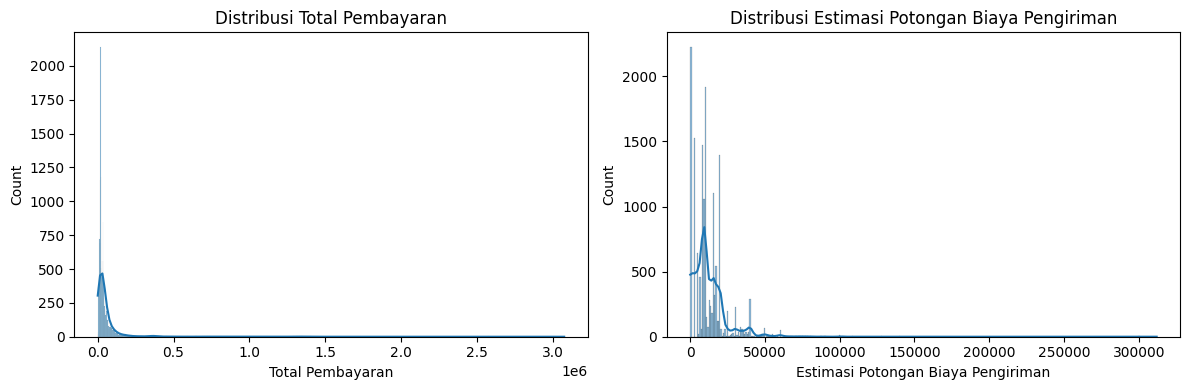

In [80]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# distribusi 'Total Pembayaran'
sns.histplot(df_bayar['Total Pembayaran'], kde=True, ax=axes[0])
axes[0].set_title('Distribusi Total Pembayaran')

# Distribusi 'Estimasi Potongan Biaya Pengiriman'
sns.histplot(df_bayar['Estimasi Potongan Biaya Pengiriman'], kde=True, ax=axes[1])
axes[1].set_title('Distribusi Estimasi Potongan Biaya Pengiriman')

plt.tight_layout()
plt.show()

Analisis Univariat

In [68]:
# Variabel analisis
num_cols = ['Total Pembayaran', 'Estimasi Potongan Biaya Pengiriman', 'total_qty', 'total_weight_gr']

# Statistik deskriptik univariat
univariate_summary = pd.DataFrame({
    'Mean': df_bayar[num_cols].mean(),
    'Median': df_bayar[num_cols].median(),
    'Modus': df_bayar[num_cols].mode().iloc[0],
    'Std Dev': df_bayar[num_cols].std(),
    'Min': df_bayar[num_cols].min(),
    'Max': df_bayar[num_cols].max(),
    'Skewness': df_bayar[num_cols].skew()
}).round(2)

display(univariate_summary)

,Mean,Median,Modus,Std Dev,Min,Max,Skewness
Total Pembayaran,59265.96,26896.0,18900.0,153410.12,165.0,3076000.0,10.01
Estimasi Potongan Biaya Pengiriman,12290.88,10000.0,0.0,12624.46,0.0,312000.0,5.29
total_qty,2.48,1.0,1.0,7.16,1.0,256.0,19.75
total_weight_gr,1898.24,500.0,500.0,5960.92,10.0,192500.0,12.95


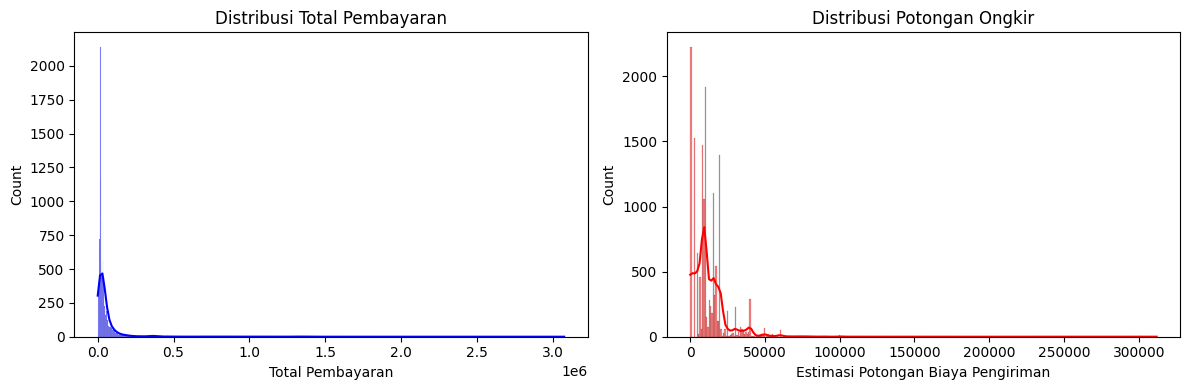

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

#Total Pembayaran
sns.histplot(df_bayar['Total Pembayaran'], kde=True, ax=axes[0], color='blue')
axes[0].set_title('Distribusi Total Pembayaran')

#Estimasi Potongan Biaya Pengiriman
sns.histplot(df_bayar['Estimasi Potongan Biaya Pengiriman'], kde=True, ax=axes[1], color='red')
axes[1].set_title('Distribusi Potongan Ongkir')

plt.tight_layout()
plt.show()

Analisis Bivariat

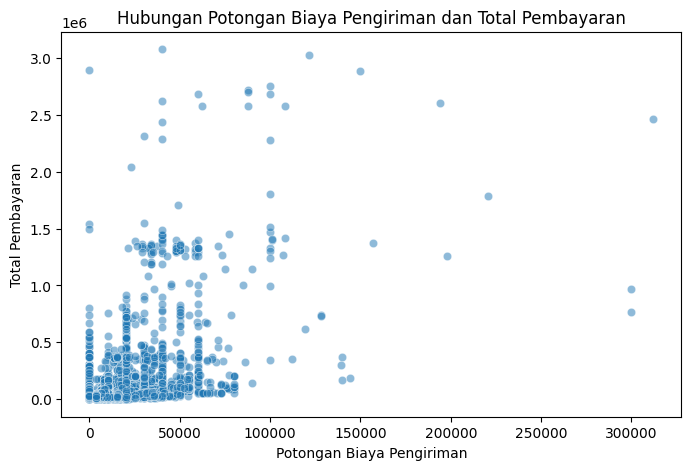

In [70]:
# Scatter Plot Bivariat
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_bayar,
    x='Estimasi Potongan Biaya Pengiriman',
    y='Total Pembayaran',
    alpha=0.5,
)

plt.title('Hubungan Potongan Biaya Pengiriman dan Total Pembayaran')
plt.xlabel('Potongan Biaya Pengiriman')
plt.ylabel('Total Pembayaran')
plt.show()

Analisis Multivariat

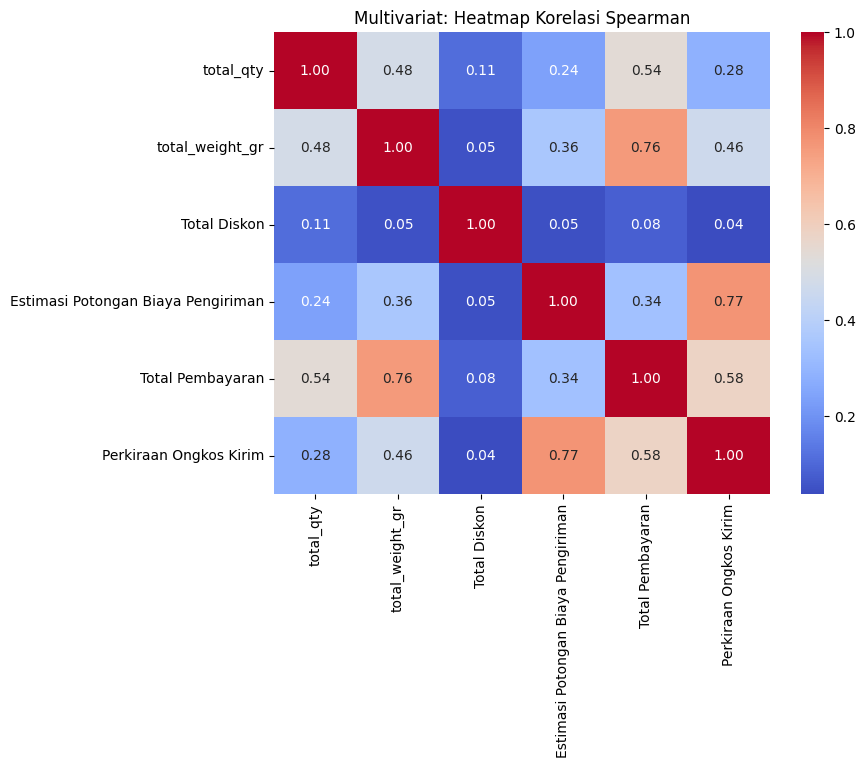

In [71]:
# Variabel numerik
num_cols = [
    'total_qty',
    'total_weight_gr',
    'Total Diskon',
    'Estimasi Potongan Biaya Pengiriman',
    'Total Pembayaran',
    'Perkiraan Ongkos Kirim'
]

# Heatmap Korelasi Spearman
plt.figure(figsize=(8, 6))

sns.heatmap(df_bayar[num_cols].corr(method='spearman'), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Multivariat: Heatmap Korelasi Spearman')
plt.show()

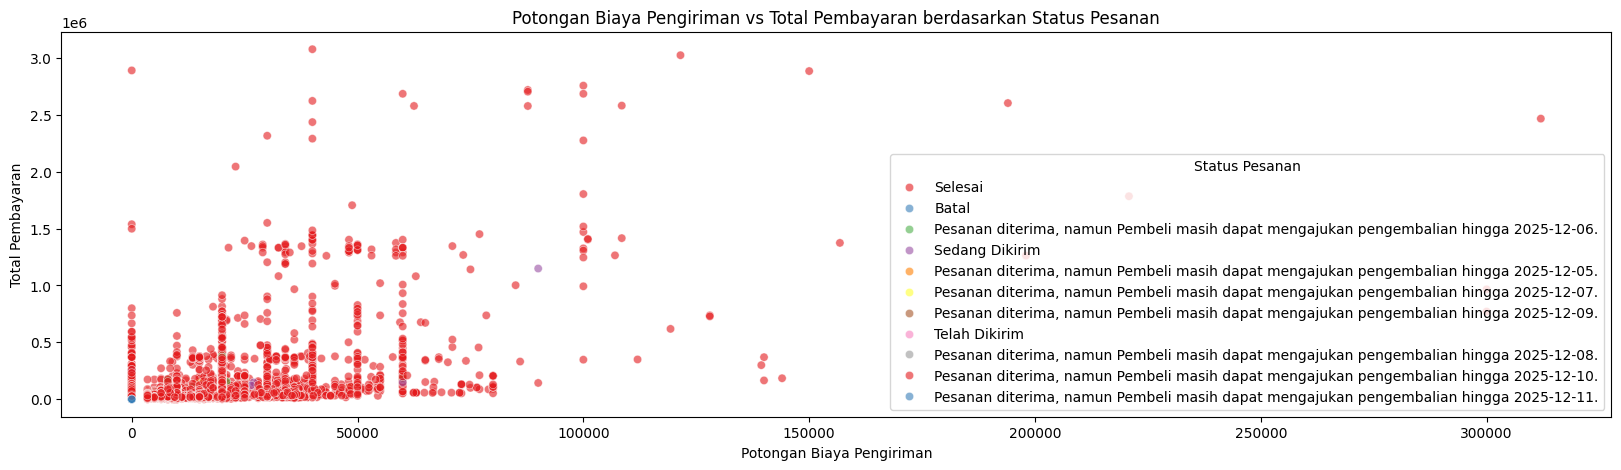

In [22]:
#Scatter Plot berdasarkan status pesanan & termasuk pesanan batal
plt.figure(figsize=(20, 5))

sns.scatterplot(
    data=df_clean,
    x='Estimasi Potongan Biaya Pengiriman',
    y='Total Pembayaran',
    hue='Status Pesanan',
    palette='Set1',
    alpha=0.6
)

plt.title('Potongan Biaya Pengiriman vs Total Pembayaran berdasarkan Status Pesanan')
plt.xlabel('Potongan Biaya Pengiriman')
plt.ylabel('Total Pembayaran')
plt.show()

**STATISTICS & EXPLORATORY DATA**

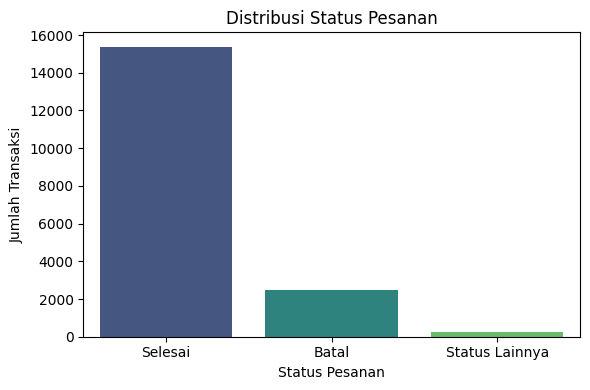

In [85]:
# Distribusi berdasarkan status pesanan
plt.figure(figsize=(6, 4))

status_counts = df_clean['Status Pesanan'].apply(lambda x: x if x in ['Selesai', 'Batal'] else 'Status Lainnya').value_counts()

sns.barplot(
    x=status_counts.index,
    y=status_counts.values,
    hue=status_counts.index,
    palette='viridis',
    legend=False)

plt.title('Distribusi Status Pesanan')
plt.xlabel('Status Pesanan')
plt.ylabel('Jumlah Transaksi')
plt.tight_layout()
plt.show()

Grafik ini menunjukkan perbandingan antara pesanan yang berhasil diselesaikan (Selesai) dengan pesanan yang dibatalkan (Batal). Mayoritas besar transaksi dalam dataset ini berstatus Selesai (mencapai belasan ribu transaksi), yang menunjukkan performa operasional toko online yang cukup baik dengan tingkat pembatalan yang relatif kecil dibandingkan total keseluruhan transaksi.

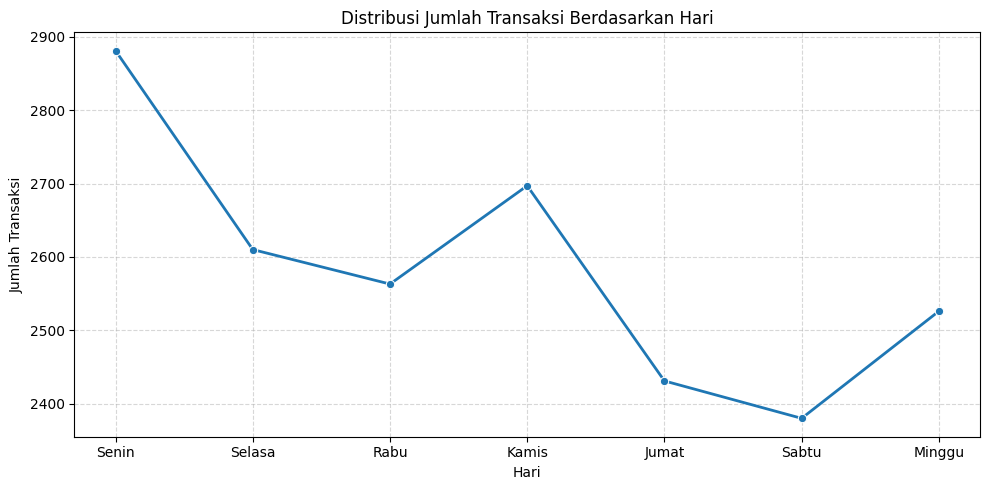

In [24]:
# Pengelompokan 'order_date' berdasarkan hari
df_clean['order_dayofweek'] = df_clean['order_date'].dt.dayofweek

day_sales = df_clean.groupby(['order_dayofweek']).size().reset_index(name='jumlah_transaksi')

# Ubah angka menjadi nama hari
nama_hari = {
    0: 'Senin',
    1: 'Selasa',
    2: 'Rabu',
    3: 'Kamis',
    4: 'Jumat',
    5: 'Sabtu',
    6: 'Minggu'
}
day_sales['hari'] = day_sales['order_dayofweek'].map(nama_hari)
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=day_sales,
    x='hari',
    y='jumlah_transaksi',
    marker='o',
    linewidth=2)

plt.title('Distribusi Jumlah Transaksi Berdasarkan Hari')
plt.xlabel('Hari')
plt.ylabel('Jumlah Transaksi')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

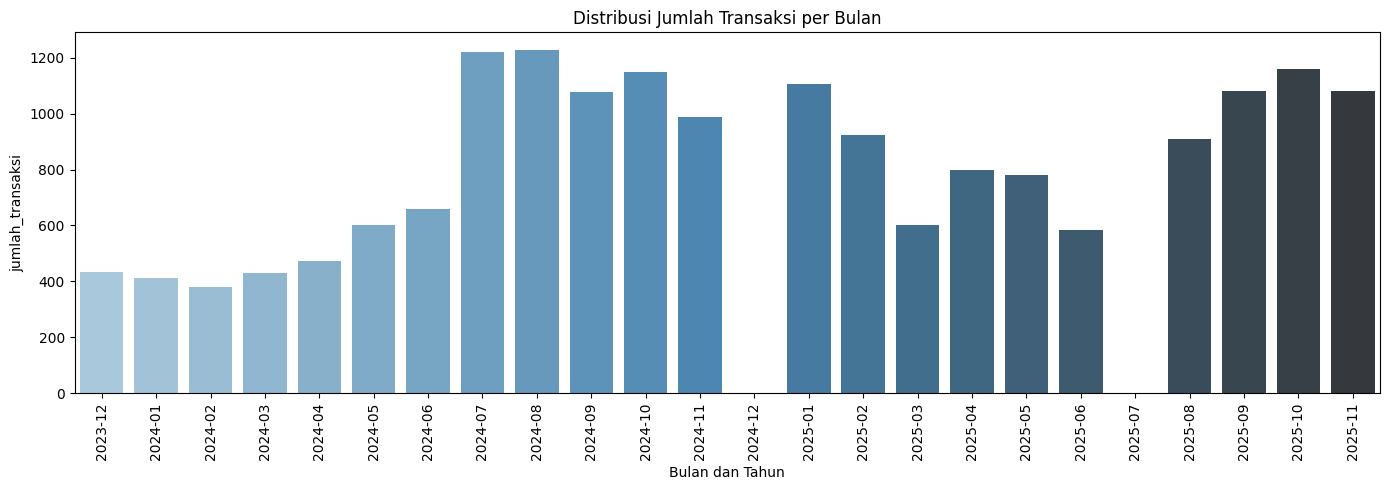

In [83]:
# Pengelompokan transaksi berdasarkan bulan dan tahun
df_clean['bulan_tahun'] = (df_clean['order_date'].dt.to_period('M').astype(str))

monthly_sales = (df_clean.groupby('bulan_tahun').size()
                 .reindex(pd.period_range('2023-12', '2025-11', freq='M').astype(str), fill_value=0) 1
                 .rename_axis('bulan_tahun')
                 .reset_index(name='jumlah_transaksi'))

plt.figure(figsize=(14, 5))

sns.barplot(
    data=monthly_sales,
    x='bulan_tahun',
    y='jumlah_transaksi',
    hue='bulan_tahun',
    palette='Blues_d',
    legend=False
)

plt.title('Distribusi Jumlah Transaksi per Bulan')
plt.xlabel('Bulan dan Tahun')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Puncak Penjualan: Transaksi tertinggi terjadi pada pertengahan tahun 2024 (terutama Juli & Agustus 2024) dengan volume mencapai lebih dari 1.200 transaksi per bulan.

Tren Stabil di Akhir Periode: Menjelang akhir tahun 2025 (Agustus - November 2025), jumlah transaksi kembali mengalami tren kenaikan yang cukup konsisten di kisaran 1.000+ transaksi per bulan.

Periode Awal & Penurunan: Penjualan terendah tercatat pada awal masa pengamatan (Desember 2023 - Februari 2024) serta sekitar awal hingga pertengahan 2025 sebelum kembali merangkak naik.




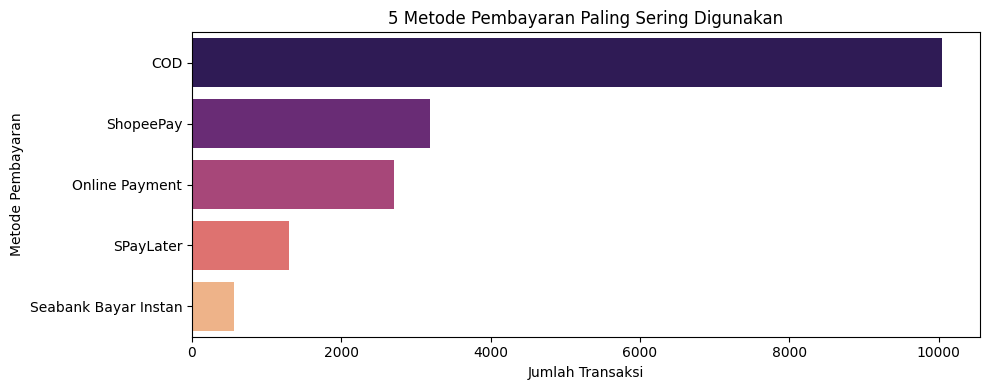

In [26]:
plt.figure(figsize=(10, 4))

# Menghitung 5 metode pembayaran yang sering digunakan
top_pay = df_clean['Metode Pembayaran'].value_counts().head(5)

sns.barplot(
    x=top_pay.values,
    y=top_pay.index,
    hue=top_pay.index,
    palette='magma',
    legend=False)

plt.title('5 Metode Pembayaran Paling Sering Digunakan')
plt.xlabel('Jumlah Transaksi')
plt.ylabel('Metode Pembayaran')
plt.tight_layout()
plt.show()

Grafik ini mengidentifikasi 5 metode pembayaran teratas yang paling diminati oleh pelanggan. Metode pembayaran COD mendominasi secara signifikan dibandingkan metode lainnya (seperti ShopeePay, Online Payment, dan SPayLater). Hal ini mencerminkan bahwa mayoritas pembeli e-commerce ini masih mengandalkan sistem pembayaran tunai saat barang diterima sebagai opsi yang paling tepercaya atau praktis bagi mereka.

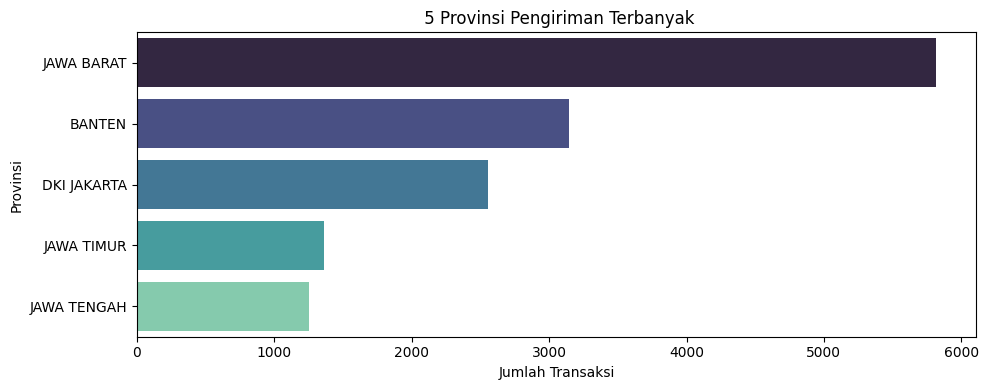

In [27]:
plt.figure(figsize=(10, 4))

# Menghitung 5 provinsi dengan jumlah transaksi terbanyak
top_prov = df_clean['Provinsi'].value_counts().head(5)

sns.barplot(
    x=top_prov.values,
    y=top_prov.index,
    hue=top_prov.index,
    palette='mako',
    legend=False
)

plt.title(' 5 Provinsi Pengiriman Terbanyak')
plt.xlabel('Jumlah Transaksi')
plt.ylabel('Provinsi')
plt.tight_layout()
plt.show()

Grafik ini memetakan 5 wilayah provinsi dengan volume pesanan/pengiriman terbanyak. Jawa Barat menempati urutan pertama dengan jumlah transaksi tertinggi, diikuti oleh Banten dan DKI Jakarta. Konsentrasi pembeli yang sangat tinggi di pulau Jawa (terutama wilayah Jabodetabek dan Jawa Barat) mengindikasikan bahwa pasar utama produk ini terkonsentrasi di area perkotaan dengan penetrasi logistik yang padat.

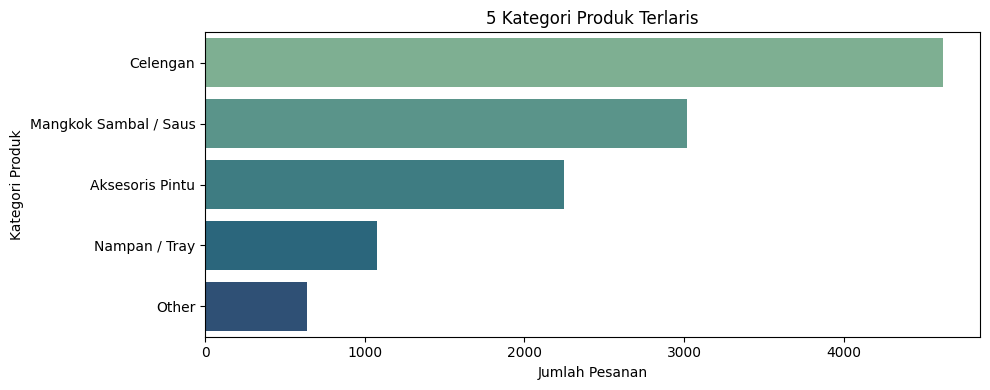

In [84]:
plt.figure(figsize=(10, 4))

# Menghitung 5 kategori produk paling laris
top_category = (df_bayar['product_categories']
                .str.split(',').explode().str.strip()
                .value_counts().head(5))

sns.barplot(
    x=top_category.values,
    y=top_category.index,
    hue=top_category.index,
    palette='crest',
    legend=False)

plt.title('5 Kategori Produk Terlaris')
plt.xlabel('Jumlah Pesanan')
plt.ylabel('Kategori Produk')
plt.tight_layout()
plt.show()

Grafik ini mengupas kategori produk apa saja yang paling diminati oleh pelanggan e-commerce, sehingga kita bisa tahu produk jenis apa yang menjadi penggerak utama penjualan toko online ini.

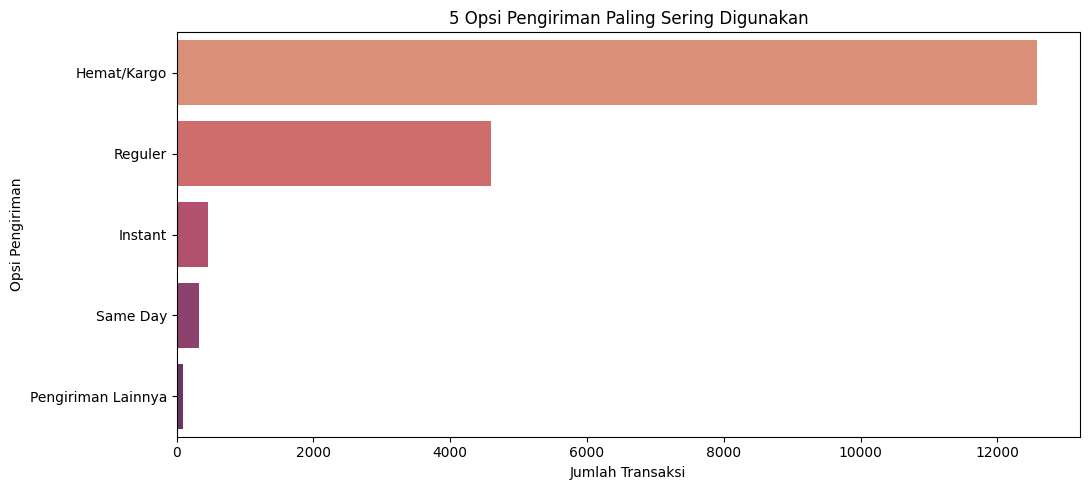

In [29]:
plt.figure(figsize=(11, 5))

# Menghitung 5 opsi pengiriman paling sering digunakan
pengiriman = df_clean['Opsi Pengiriman'].value_counts().head(5)

sns.barplot(
    x=pengiriman.values,
    y=pengiriman.index,
    hue=pengiriman.index,
    palette='flare',
    legend=False
)
plt.title('5 Opsi Pengiriman Paling Sering Digunakan')
plt.xlabel('Jumlah Transaksi')
plt.ylabel('Opsi Pengiriman')
plt.tight_layout()
plt.show()

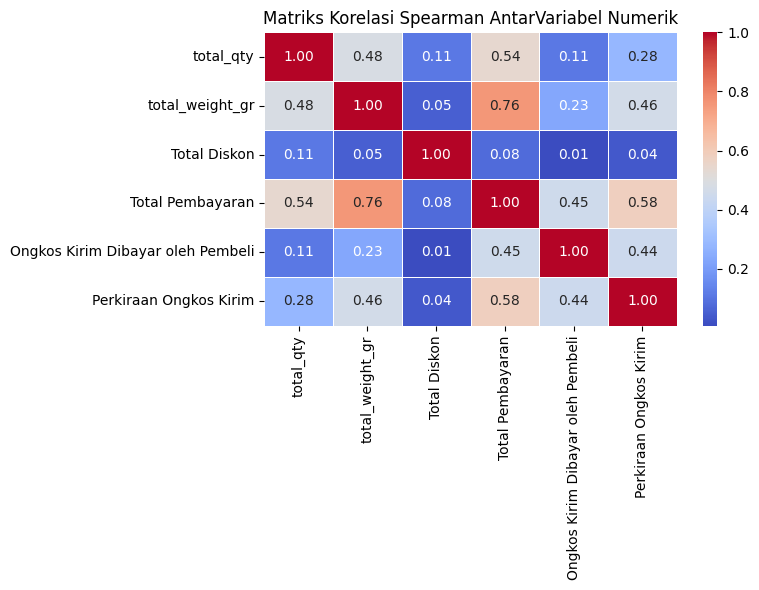

In [72]:
plt.figure(figsize=(8, 6))

# Variabel numerik yang dianalisi
num_cols = [
    'total_qty',
    'total_weight_gr',
    'Total Diskon',
    'Total Pembayaran',
    'Ongkos Kirim Dibayar oleh Pembeli',
    'Perkiraan Ongkos Kirim'
]

# Menghitung Korelasi Spearman
korelasi = df_bayar[num_cols].corr(method='spearman')

sns.heatmap(
    korelasi,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5)

plt.title('Matriks Korelasi Spearman AntarVariabel Numerik')
plt.tight_layout()
plt.show()

Heatmap ini memperlihatkan hubungan erat antar variabel angka. Terlihat bahwa Perkiraan Ongkos Kirim memiliki korelasi yang kuat dengan total_weight_gr (berat barang), yang sangat masuk akal karena tarif ongkir logistik dihitung berdasarkan berat total paket yang dikirimkan.

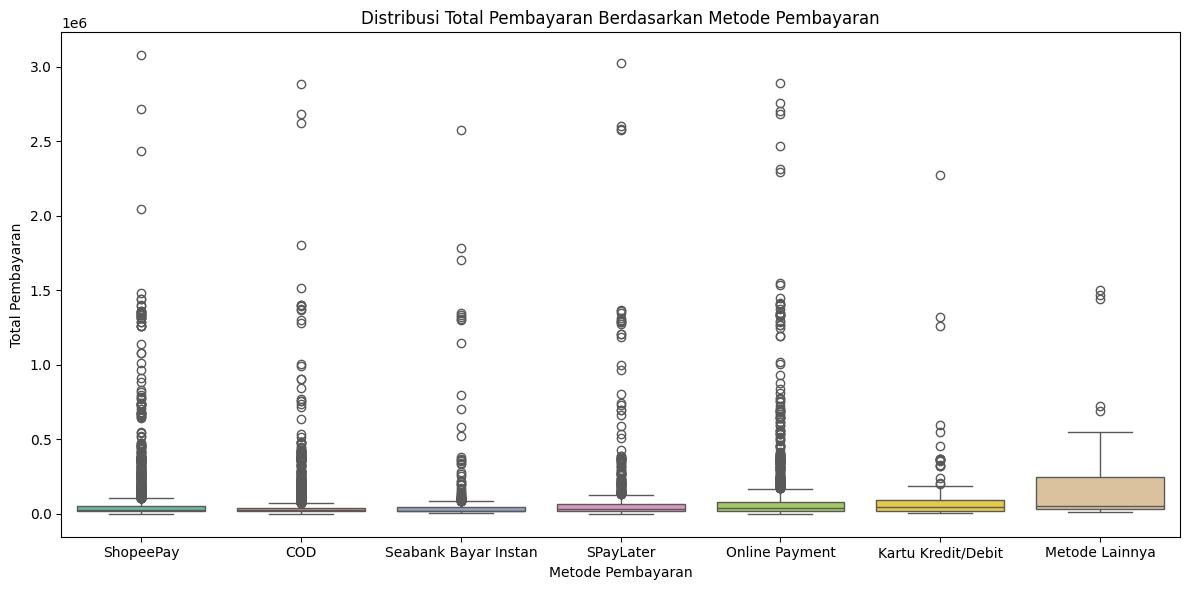

In [73]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_bayar,
    x='Metode Pembayaran',
    y='Total Pembayaran',
    hue='Metode Pembayaran',
    palette='Set2',
    legend=False
)

plt.title('Distribusi Total Pembayaran Berdasarkan Metode Pembayaran')
plt.xlabel('Metode Pembayaran')
plt.ylabel('Total Pembayaran')
plt.tight_layout()
plt.show()

**MACHINE LEARNING**  
Prediksi Pendapatan Bersih yang Diterima

In [97]:
# Mengambil transaksi berhasil
df_model = df_clean[(df_clean['Status Pesanan'] != 'Batal') & (df_clean['Total Pembayaran'] > 0)].copy()

# Hapus kolom untuk hindari data leak
leakage_and_id_cols = ['order_id', 'Status Pesanan', 'Alasan Pembatalan', 'total_returned_qty']
df_model = df_model.drop(columns=[col for col in leakage_and_id_cols if col in df_model.columns])

# Format
df_model = df_model.sort_values('Waktu Pesanan Dibuat').reset_index(drop=True)

In [98]:
# Time-Based & Train-Test Split
split_idx = int(len(df_model) * 0.8)

train_df = df_model.iloc[:split_idx].copy()
test_df = df_model.iloc[split_idx:].copy()

print(f"Jumlah Data Train: {len(train_df)} | Jumlah Data Test: {len(test_df)}")

Jumlah Data Train: 12449 | Jumlah Data Test: 3113


In [99]:
num_skewed = ['total_qty', 'total_weight_gr', 'Total Diskon', 'Ongkos Kirim Dibayar oleh Pembeli']

# Log-transform kategori numerik
for col in num_skewed:
    train_df[f'{col}_log'] = np.log1p(train_df[col])
    test_df[f'{col}_log'] = np.log1p(test_df[col])

# Log-transform 'Total Pembayaran'
y_train_log = np.log1p(train_df['Total Pembayaran'])
y_test_log = np.log1p(test_df['Total Pembayaran'])

In [100]:
category_cols = ['product_categories', 'Opsi Pengiriman', 'Metode Pembayaran', 'Kota/Kabupaten']

for col in category_cols:
    # Hitung frekuensi data train
    freq_map = train_df[col].value_counts(normalize=True).to_dict()

    # Map ke train dan test & mengisi nilai 0 jika ada kategori baru di
    train_df[f'{col}_freq'] = train_df[col].map(freq_map).fillna(0)
    test_df[f'{col}_freq'] = test_df[col].map(freq_map).fillna(0)

In [101]:
# Fitur yang digunakan
features = [
    'num_product_categories',
    'total_qty_log', 'total_weight_gr_log', 'Total Diskon_log', 'Ongkos Kirim Dibayar oleh Pembeli_log',
    'product_categories_freq', 'Opsi Pengiriman_freq', 'Metode Pembayaran_freq', 'Kota/Kabupaten_freq'
]

X_train = train_df[features]
X_test = test_df[features]

y_train = y_train_log
y_test = y_test_log

In [113]:
# Inisialisasi & Latih Model X
xgb_model = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
xgb_model.fit(X_train, y_train)

# Prediksi & Kembalikan ke Skala Rupiah
y_pred_xgb = np.expm1(xgb_model.predict(X_test))
y_test_actual = np.expm1(y_test)

# Hitung Evaluasi Performa
mae = mean_absolute_error(y_test_actual, y_pred_xgb)
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_xgb))
r2 = r2_score(y_test_actual, y_pred_xgb)

# Hasil
df_eval = pd.DataFrame({
    'Model': ['XGBoost'],
    'MAE': [f"Rp {mae:,.2f}"],
    'RMSE': [f"Rp {rmse:,.2f}"],
    'R2 Score': [f"{r2:.4f}"]
})
df_eval

,Model,MAE,RMSE,R2 Score
0,XGBoost,"Rp 8,930.41","Rp 56,325.21",0.8427


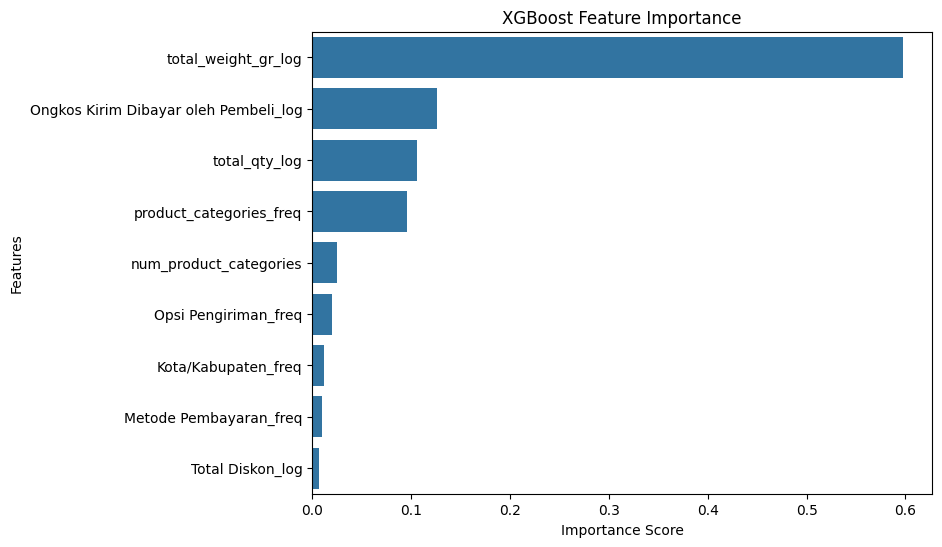

In [116]:
# feature importance dari model XGBoost
importances = xgb_model.feature_importances_

# Visualisasi
feature_importances = pd.Series(importances, index=X_train.columns).sort_values(ascending=False)

# Plot
plt.figure(figsize=(8, 6))
sns.barplot(x=feature_importances.values, y=feature_importances.index)
plt.title('XGBoost Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

In [117]:
# Menyimpan model
joblib.dump(xgb_model, 'xgboost_model.joblib')

# Menyimpan fitur
joblib.dump(features, 'model_features.joblib')

# Menyimpan frekuensi untuk kolom kategorikal
freq_maps = {}
category_cols = ['product_categories', 'Opsi Pengiriman', 'Metode Pembayaran', 'Kota/Kabupaten']

for col in category_cols:
    freq_maps[col] = train_df[col].value_counts(normalize=True).to_dict() # Menghitung frekuensi data train_df

joblib.dump(freq_maps, 'freq_maps.joblib')

# hasil
print("Model, fitur, dan frekuensi berhasil tersimpan")

Model, fitur, dan frekuensi berhasil tersimpan
